The bulk of Gaia XP spectra at Gaia DR3 are provided in a parametric "continuous" representational form (as opposed to conventional sampled form, i.e. fluxes in wavelength bins) in table `GDR3_XP_CONTINUOUS_MEAN_SPECTRUM`. Utilities for handling this form, including conversion to sampled form and plotting, are provided in a bespoke Python package [GaiaXPy](https://gaia-dpci.github.io/GaiaXPy-website/) which is available on this platform. A small subset of the XP spectra are provided also in sampled form in table `GDR3_XP_SAMPLED_MEAN_SPECTRUM` but these are for illustrative purposes only: users are strongly encouraged to familiarise themselves and work with the continuous representation, not least in order to handle correctly the statistical uncertainties inherent to the data.

To access GaiaXPy on this platform simply import the package as follows:

    import gaiaxpy

then all classes and utility functions etc. will be available.

The code in the following cells illustrates a workflow where we trawl through the a large XP spectral data looking for spectra similar to a high signal-to-noise template example. The implementation takes advantage of the end-user programmability of the distributed query execution engine to return results in a reasonable time. The approach is to look for spectra having the same spectral shape, as expressed in the coefficients of the continuous representation.

In [ ]:
from dask.distributed import Client
from dask.distributed import print as dprint
import dask.dataframe as dd
import dask
from dask.delayed import delayed
import numpy as np
import pandas as pd
from gaiaxpy import calibrate
from gaiaxpy import plot_spectra, convert
import time
import os
from pathlib import Path

# Set up the client
c = Client('tcp://simple-scheduler.dask-operator.svc.cluster.local:8786')
print(c)

# Define some constants

# static constants for use when reconstructing a covariance matrix from the flattened upper-triangular correlation matrix stored in xp_continuous_mean_spectrum
NUM_XP_COEFFS = 55
# these indexes define the column-major positions of the correlation vector elements in the lower triangle of the 2d correlation matrix ...
lower_index = np.tril_indices(NUM_XP_COEFFS,-1)
# ... note that numpy indexing is row-major. The upper triangular index is created from the lower, reflecting across the diagonal,
# by transposing the axes - this results in the required column-major indexing for the upper part
upper_index = (lower_index[1], lower_index[0])
# correlation matrix, empty apart from unity on the diagonal (off-diagonal elements to be filled in on a case-by-case basis)
correlation_matrix = np.diag(np.ones(NUM_XP_COEFFS))

# Define the file paths
source_files = Path(os.environ['DASK_DATA_PATH_GAIA_DR3_SSD']).joinpath('GDR3_GAIA_SOURCE')
xp_files = Path(os.environ['DASK_DATA_PATH_GAIA_DR3_SSD']).joinpath('GDR3_XP_CONTINUOUS_MEAN_SPECTRUM')

template_sid=5853498713190525696

<Client: 'tcp://192.168.63.173:8786' processes=10 threads=60, memory=250.00 GiB>


/usr/local/lib/python3.10/site-packages/distributed/client.py:1612: VersionMismatchWarning: Mismatched versions found

+---------+-----------------+-----------------+-----------------+
| Package | Client          | Scheduler       | Workers         |
+---------+-----------------+-----------------+-----------------+
| lz4     | 4.4.4           | 4.3.3           | 4.3.3           |
| numpy   | 2.2.6           | 2.2.2           | 2.2.2           |
| python  | 3.10.16.final.0 | 3.10.12.final.0 | 3.10.12.final.0 |
| toolz   | 1.0.0           | 0.12.0          | 0.12.0          |
| tornado | 6.4.1           | 6.4.2           | 6.4.2           |
+---------+-----------------+-----------------+-----------------+
  warnings.warn(version_module.VersionMismatchWarning(msg[0]["warning"]))


Thresholds are 378.3741455078125 556.6802978515625


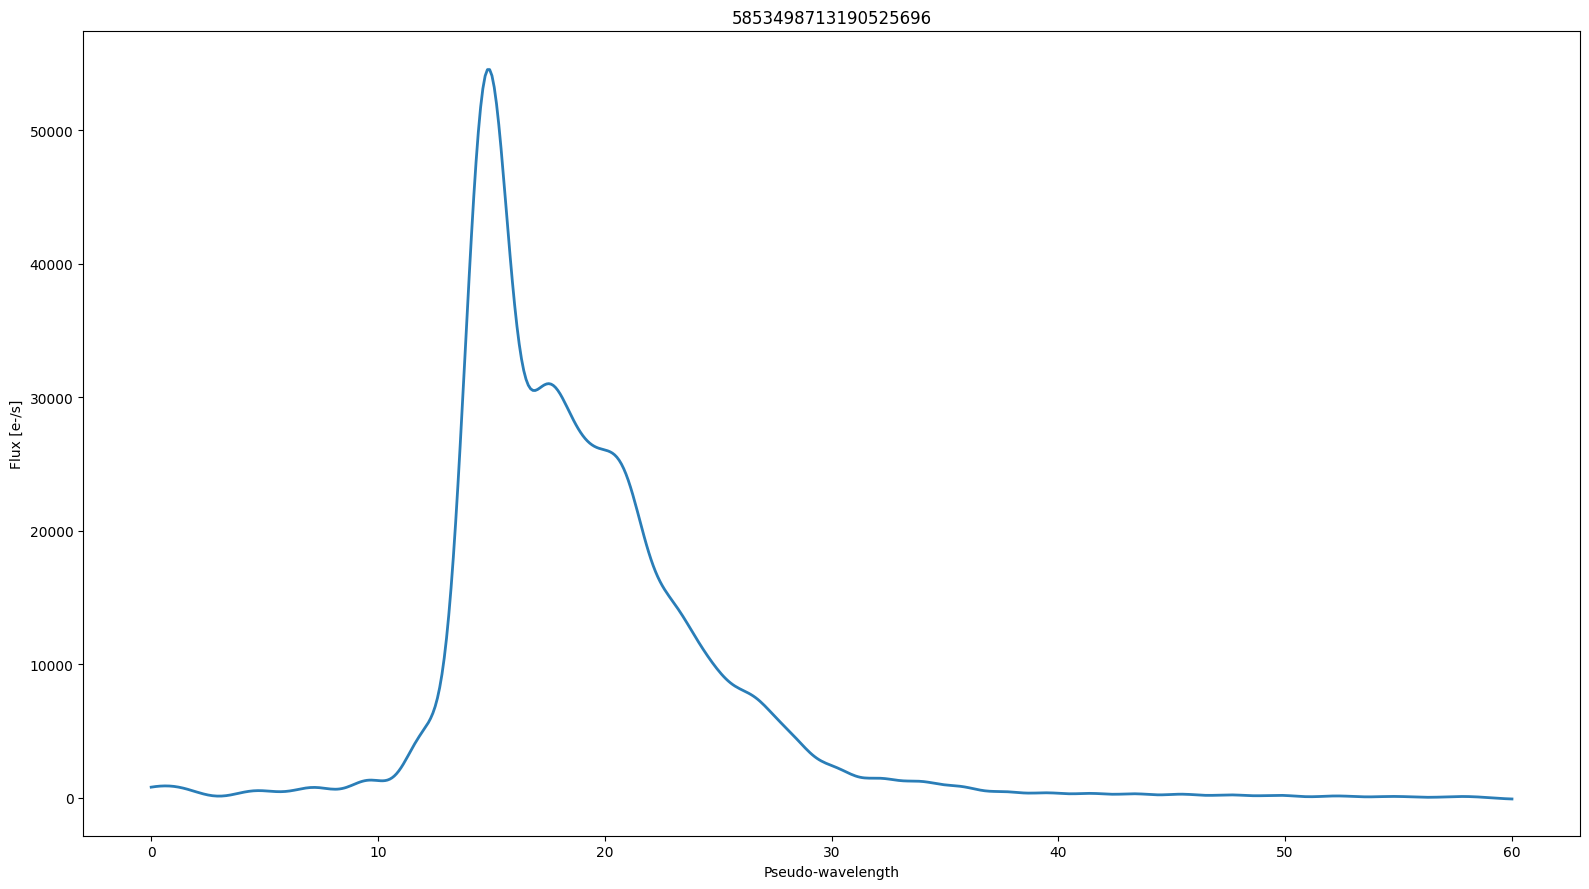

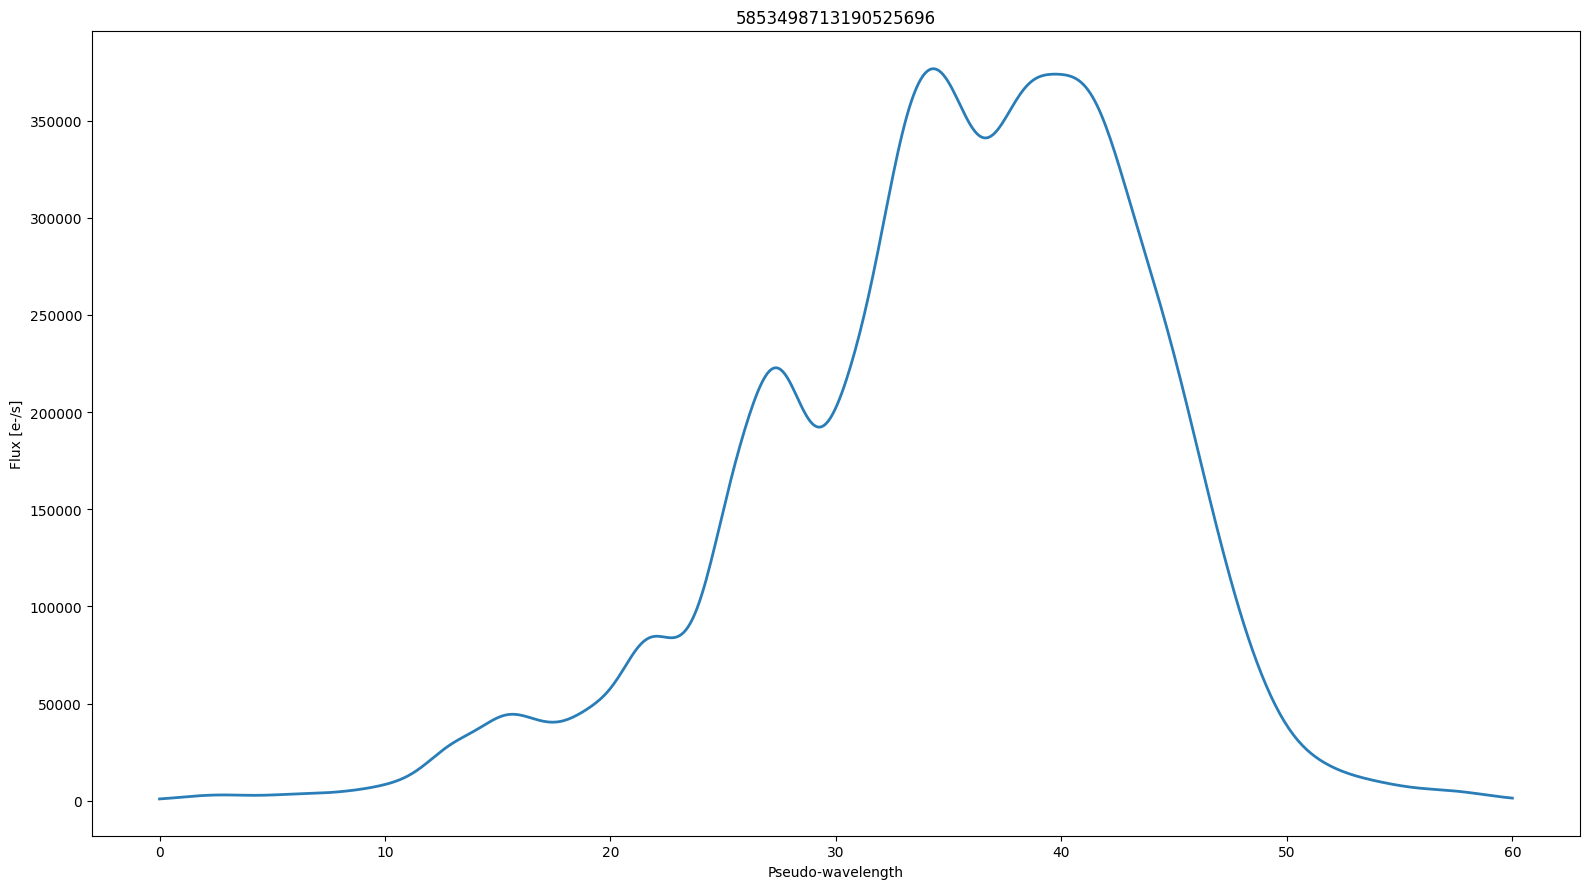

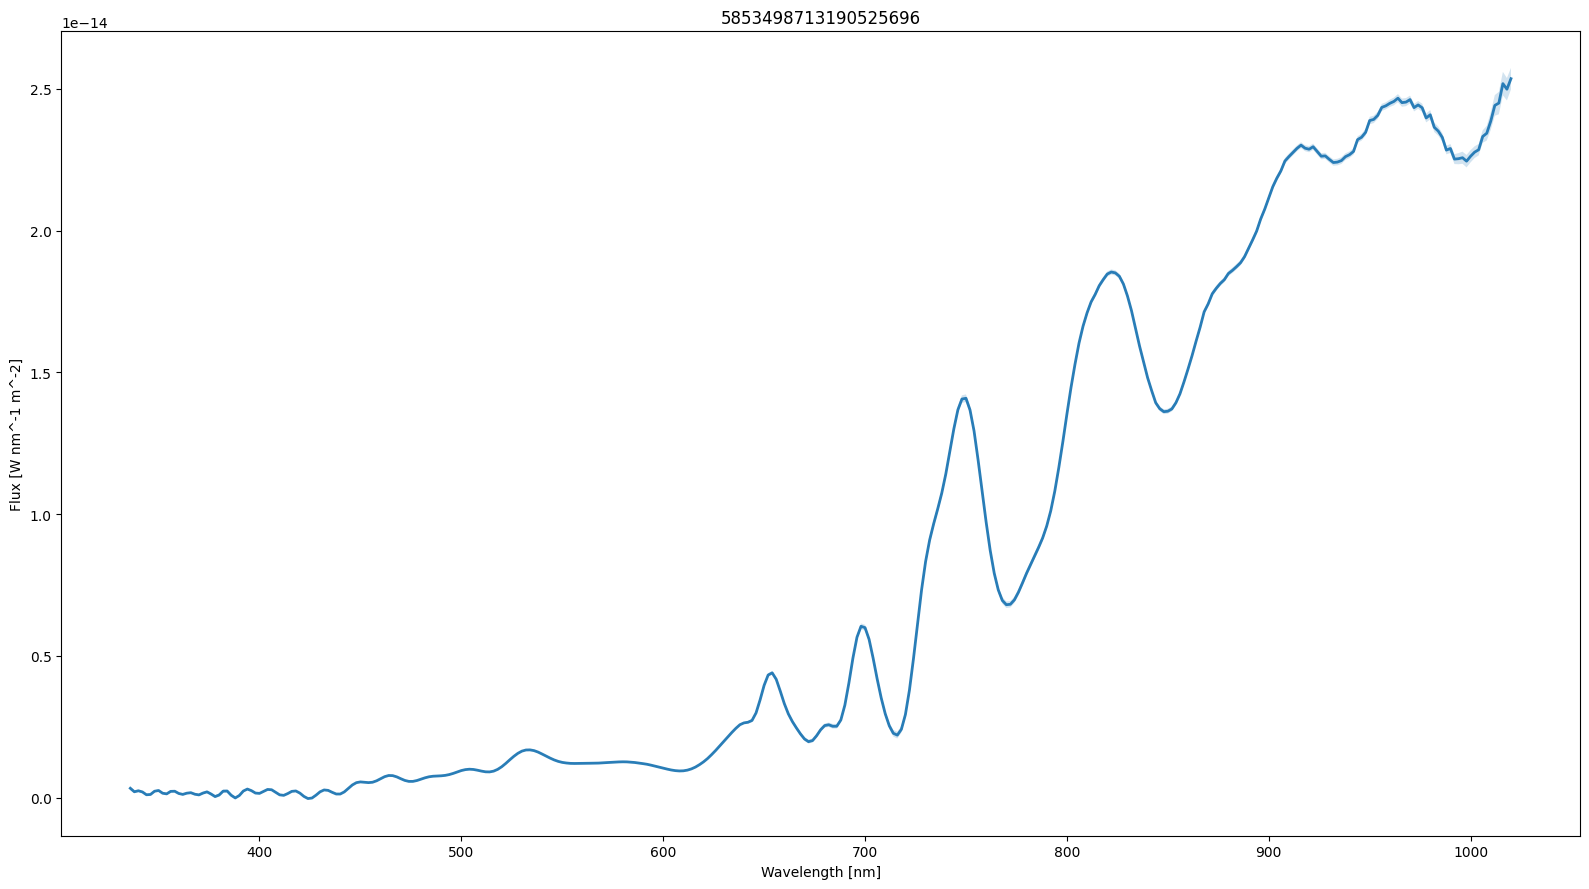

In [ ]:
# Find the template records and join to make df
continuous_df = dd.read_parquet(xp_files,                                
                                filters=[('source_id', '=', template_sid),]
)

source_df = dd.read_parquet(source_files,                                
                                filters=[('source_id', '=', template_sid),]
)

template_df = source_df[['phot_g_mean_mag', 'phot_bp_mean_flux_over_error', 'phot_rp_mean_flux_over_error']].join(continuous_df, how='inner').compute().reset_index()
template_row = template_df.iloc[0]

thresh_bp = 0.9 * template_row['phot_bp_mean_flux_over_error']
thresh_rp = 0.9 * template_row['phot_rp_mean_flux_over_error']
dprint(f'Thresholds are {thresh_bp} {thresh_rp}')

# Get the DF
continuous_spectrum = continuous_df.head(npartitions=-1).reset_index()

# convert to sampled form:
sampled_spectrum, sampling = convert(continuous_spectrum, save_file = False)

# plot to sanity check:
plot_spectra(sampled_spectrum, sampling = sampling, multi=False, show_plot=True, output_path=None, legend=True)

# GaiaXPy provides classes and methods to create an externally calibrated single spectrum from the internal XP continuous representation:
calibrated_spectrum, sampling = calibrate(continuous_spectrum, save_file = False)

# plot it
plot_spectra(calibrated_spectrum, sampling = sampling, legend = False)

In [5]:
def xp_mahalanobis_distance(coeff_vector_1 : np.ndarray, covariance_1 : np.ndarray,
        coeff_vector_2 : np.ndarray, error_vector_2 : np.ndarray, correlation_vector_2 : np.ndarray) -> float:
    '''
    Computes the Mahalanobis distance between two XP spectra given template coefficients and fully populated
    covariance for the first, and the data record of the second candidate spectrum, i.e. coefficients, errors and 
    upper-triangular part of the correlation matrix in the continuous representation. The second set of
    coefficients and errors should be scaled to the same flux level as the template spectrum. This means that
    the distance returned quantifies how close the candidate SED shape is to that of the template regardless any
    difference in intrinsic luminosity.
    
    This function uses plain matrix inversion of the combined covariance matrix. This can be numerically unstable
    and result in a negative squared distance resulting in turn in a return value of not-a-number. It is up to 
    the calling application to handle this condition.
    '''
    # second covariance matrix
    corr2 = make_correlation_matrix(correlation_vector_2)
    covariance_2 = make_covariance_matrix(corr2, error_vector_2)
    
    # form covariance of the coefficient difference vector as sum of individual covariance 
    cocovar = covariance_1 + covariance_2
    
    # inverse of combined, scaled covariance
    cocovar_inv = np.linalg.inv(cocovar)

    # use these in the computation of the square of the Mahalanobis distance, e.g. see source linked from
    # https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.mahalanobis.html
    delta = coeff_vector_1 - coeff_vector_2
    d = np.sqrt(np.dot(np.dot(delta, cocovar_inv), delta))
    
    # resulting Mahalanobis distance follows chi distribution with NUM_XP_COEFFS degrees of freedom (M. Weiler, personal communication)
    # for identical spectra
    return d

def xp_mahalanobis_distance_vectorised(coeff_vector_1, covariance_1, coeff_vector_2, error_vector_2, correlation_vector_2):
    # second covariance matrix
    corr2 = make_correlation_matrix_vectorised(correlation_vector_2)
    covariance_2 = make_covariance_matrix_vectorised(corr2, error_vector_2)

    # form covariance of the coefficient difference vector as sum of individual covariance 
    cocovar = covariance_1 + covariance_2
    
    # inverse of combined, scaled covariance
    cocovar_inv = np.linalg.inv(cocovar)
    
    # use these in the computation of the square of the Mahalanobis distance, e.g. see source linked from
    # https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.mahalanobis.html
    delta = np.vstack([coeff_vector_1]*coeff_vector_2.shape[0]) - coeff_vector_2
    # s1 = np.einsum('ij,ijk -> ik', delta, cocovar_inv)
    s1 = np.matmul(delta[:, np.newaxis, :], cocovar_inv).squeeze(1)
    s2 = np.einsum('ij,ij->i', s1, delta)
    # Could also use s2 = np.sum(s1 * delta, axis=1)
    d = np.sqrt(s2)

    # resulting Mahalanobis distance follows chi distribution with NUM_XP_COEFFS degrees of freedom (M. Weiler, personal communication)
    # for identical spectra
    
    return d

def make_correlation_matrix(correlation_vector : np.ndarray) -> np.ndarray:
    '''
    Returns the fully populated 2d correlation matrix given the flattened, 1d upper-triangular off-diagonal
    elements of the same as persisted in the table of XP continuous representation spectra.
    '''
    # copy in unique, off-diagonal elements from the flattened correlation vector into the 2d-indexed positions
    correlation_matrix[upper_index] = correlation_vector
    correlation_matrix[lower_index] = correlation_vector
    
    # give back the complete correlation matrix
    return correlation_matrix

def make_correlation_matrix_vectorised(correlation_vectors):
    '''    
    Now stacks each to match the 0th dimension of correlation_vectors, enabling vectorised calculations.

    Note: 1/3 of the calculation time is lost in this function, potential scope for optimisation.
    '''
    template = np.eye(NUM_XP_COEFFS)
    correlation_matrices = np.stack([template] * correlation_vectors.shape[0], axis=0)
    correlation_matrices[:, upper_index[0], upper_index[1]] = correlation_vectors
    correlation_matrices[:, lower_index[0], lower_index[1]] = correlation_vectors
    return correlation_matrices

def make_covariance_matrix(complete_correlation_matrix : np.ndarray, coefficient_error_vector : np.ndarray) -> np.ndarray:
    '''
    Creates the fully reconstructed 2d covariance matrix of an XP continuous representation spectrum given the
    complete 2d correlation matrix and the vector of formal errors on the coefficients. Note that Gaia DPAC CU5 scale 
    predicted coefficient errors by the standard deviation as a post-hoc correction to the formal (sqrt) variances.
    GaiaXPy actually reverses this scaling in computation of the covariance matrix to return the latter as exactly
    that produced as a result of the least-squares solution for the coefficients. Such a de-scaling of the errors
    is not applied here: we assume that the uncertainties are best represented with this scaling intact.
    '''
    # 2d matrix with the errors on the diagonal
    error_matrix = np.diag(coefficient_error_vector)
    
    # from the standard relationship between covariance and correlation
    return error_matrix @ (error_matrix @ complete_correlation_matrix)

def make_covariance_matrix_vectorised(complete_correlation_matrix, coefficient_error_vector):
    '''
    Note: 1/3 of the calculation time is lost here. Further optimisation could be explored. 

    Note: I dislike the use of for i in range(N) here, perhaps there a smarter numpy way to do this. 
          It's not where most time is lost, however.
    '''
    
    N = complete_correlation_matrix.shape[0]
    error_matrices = np.array([np.diag(coefficient_error_vector[i]) for i in range(N)])
    covariance_matrices = error_matrices @ (error_matrices @ complete_correlation_matrix)
    return covariance_matrices

In [6]:
# extract the template arrays 
template_bp_coefficients = np.array(template_row['bp_coefficients']).reshape(-1)
template_bp_coefficient_errors = np.array(template_row['bp_coefficient_errors']).reshape(-1)
template_bp_correlations = np.array(template_row['bp_coefficient_correlations']).reshape(-1)
template_rp_coefficients = np.array(template_row['rp_coefficients']).reshape(-1)
template_rp_coefficient_errors = np.array(template_row['rp_coefficient_errors']).reshape(-1)
template_rp_correlations = np.array(template_row['rp_coefficient_correlations']).reshape(-1)
template_gmag = template_row['phot_g_mean_mag']

# precompute the required vectors and matrices for the template
bp_correl_mat = make_correlation_matrix(template_bp_correlations)
template_bp_covariance = make_covariance_matrix(bp_correl_mat, template_bp_coefficient_errors)
rp_correl_mat = make_correlation_matrix(template_rp_correlations)
template_rp_covariance = make_covariance_matrix(rp_correl_mat, template_rp_coefficient_errors)

In [7]:
def find_similar_continuous_spectra(part, source_df, template_bp_coefficients, template_bp_covariance, template_rp_coefficients, template_rp_covariance):
    #_start = time.time()
    #dprint(f'Starting find_similar_continuous_spectra with part {part.index.min()} -> {part.index.max()} and source_df {source_df.index.min()} -> {source_df.index.max()}')

    # Merge in the source data
    part = part.merge(source_df, how='inner', left_index=True, right_index=True)
    #_merged = time.time()
    
    if part.empty:
        return pd.DataFrame(columns=['xp_similar']).astype({'xp_similar': "float"})
    
    norm = 10.0**(0.4 * (template_gmag - part['phot_g_mean_mag']))
    bp_c_norm = np.vstack(part['bp_coefficients'] / norm)
    bp_c_e_norm = np.vstack(part['bp_coefficient_errors'] / norm)
    bp_c_c = np.vstack(part['bp_coefficient_correlations'])
    rp_c_norm = np.vstack(part['rp_coefficients'] / norm)
    rp_c_e_norm = np.vstack(part['rp_coefficient_errors'] / norm)
    rp_c_c = np.vstack(part['rp_coefficient_correlations'])
    a = xp_mahalanobis_distance_vectorised(template_bp_coefficients, template_bp_covariance, bp_c_norm, bp_c_e_norm, bp_c_c)
    b = xp_mahalanobis_distance_vectorised(template_rp_coefficients, template_rp_covariance, rp_c_norm, rp_c_e_norm, rp_c_c)
    part['xp_similar'] = np.sqrt(a * a + b * b)

    #_end = time.time()
    #dprint(f'Finished find_similar_continuous_spectra with part {part.index.min()} -> {part.index.max()} and source_df {source_df.index.min()} -> {source_df.index.max()}. Time: {_end - _start} time to merge: {_merged - _start}, time to calc: {_end - _merged}')
    return part[['xp_similar']]

In [8]:
# Only flux_over_error 53172081
# With ag_snapshot      7785835
# All filters           

In [9]:
def run():
    _start_run = time.time()
    
    cols_xp = (
        'bp_coefficients', 
        'bp_coefficient_errors', 
        'bp_coefficient_correlations', 
        'rp_coefficients', 
        'rp_coefficient_errors', 
        'rp_coefficient_correlations',
       )
    
    df = dd.read_parquet(xp_files,
                         columns = cols_xp,
                         calculate_divisions = True,
                         )
    
    cols_source = (
        'phot_g_mean_mag',
        'phot_bp_mean_flux_over_error',
        'phot_rp_mean_flux_over_error',
        'ag_gspphot', 
        'bp_rp', 
        'phot_bp_rp_excess_factor'
       )
    
    _source_df = dd.read_parquet(source_files,
                                 columns = cols_source,
                                 calculate_divisions = True,
                                 filters = [
                                     ('ag_gspphot', '<', 0.1),
                                     ('phot_bp_mean_flux_over_error', '>', thresh_bp),
                                     ('phot_rp_mean_flux_over_error', '>', thresh_rp),
                                 ],
                                 )

    # Do some additional filtering on _source_df
    # Precompute the mathematical expressions for filtering
    phot_g_term = 2.0 * (0.0059898 + 8.817481e-12 * np.power(_source_df['phot_g_mean_mag'], 7.618399))

    # Compute different conditions separately
    cond1 = (_source_df['bp_rp'] < 0.5) & (
        np.abs(_source_df['phot_bp_rp_excess_factor'] - (1.15436 + 0.033772 * _source_df['bp_rp'] + 0.032277 * _source_df['bp_rp']**2))
        < phot_g_term
    )

    cond2 = ((_source_df['bp_rp'] >= 0.5) & (_source_df['bp_rp'] <= 4.0)) & (
        np.abs(_source_df['phot_bp_rp_excess_factor'] - (1.162004 + 0.011464 * _source_df['bp_rp'] + 0.049255 * _source_df['bp_rp']**2 - 0.005879 * _source_df['bp_rp']**3))
        < phot_g_term
    )

    cond3 = (_source_df['bp_rp'] > 4.0) & (
        np.abs(_source_df['phot_bp_rp_excess_factor'] - (1.057572 + 0.0140537 * _source_df['bp_rp']))
        < phot_g_term
    )

    # Apply all conditions including g.ag_gspphot < 0.1
    _source_df = _source_df[(cond1 | cond2 | cond3)]
    _source_df = _source_df.drop(columns=['ag_gspphot', 'bp_rp', 'phot_bp_rp_excess_factor'])
    
    # df = df.repartition(npartitions=1)
    # source_df = _source_df.repartition(npartitions=1)    
    
    df_divs = list(df.divisions)
    sf_divs = _source_df.divisions
    df_divs[-1] = sf_divs[-1]  
    _source_df = _source_df.repartition(df_divs, force=True)
    #    _source_df = _source_df.repartition(npartitions=df.npartitions)
    #df.divisions = _source_df.divisions
    source_df = _source_df.persist()

    
    #print(f'df partitions = {df.npartitions}')
    #print(f'source_df partitions = {source_df.npartitions}')

    _results = dd.map_partitions(find_similar_continuous_spectra, 
                                 df, 
                                 source_df, 
                                 #df.partitions[:10], 
                                 #source_df.partitions[:10], 
                                 template_bp_coefficients, 
                                 template_bp_covariance, 
                                 template_rp_coefficients, 
                                 template_rp_covariance,                                 
                                 meta={"xp_similar": "float"}
    )

    future = c.compute(_results)
    results = future.result().sort_values('xp_similar') #.head(100)
    print(results)
    
    _end_run = time.time()
    print(f'Finished, time was {_end_run - _start_run}')
    
    results.to_parquet('run5-all-filters-results.parquet')

In [10]:
run()

                      xp_similar
source_id                       
1612801833587498240   202.300088
5249254676369630336   214.331287
6366571314402539008   225.372224
5441169002153568512   230.392419
4975847194422433280   292.065794
...                          ...
5081933161508910208  4965.330431
5618550670450300160  4980.280619
5618547161450901760  5003.212594
508018489936966656   5016.755712
1948854505920501760  5055.777353

[7218473 rows x 1 columns]
Finished, time was 5203.3630838394165


In [12]:
df = pd.read_parquet('run5-all-filters-results.parquet')

In [13]:
sources = df.head(3).reset_index()['source_id'].tolist()

cdf = dd.read_parquet(xp_files,                                
                      filters=[('source_id', 'in', sources[:-1]),]
).compute()

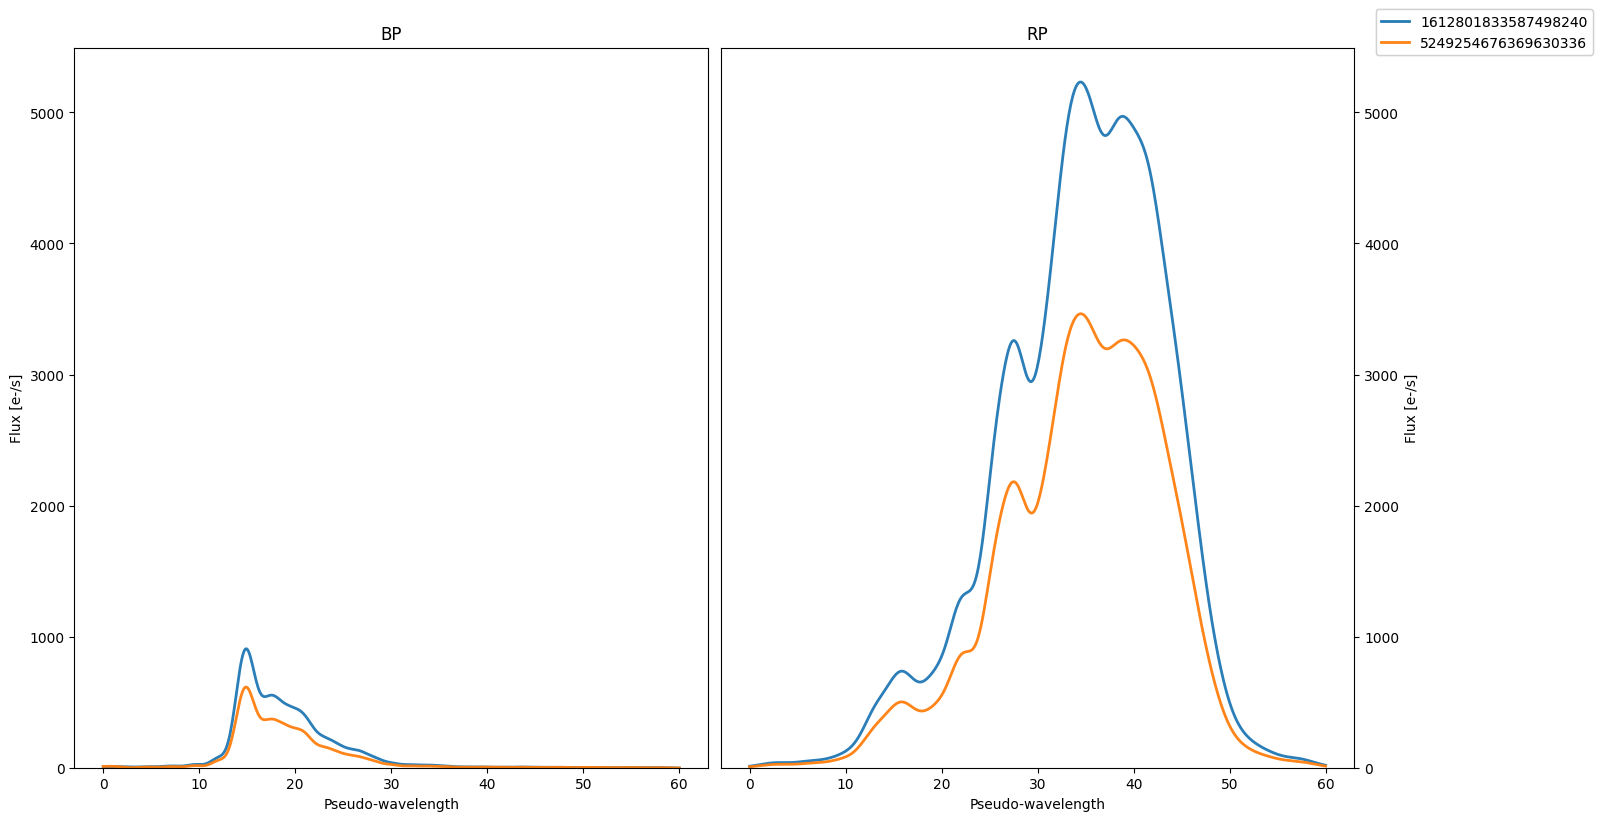

In [14]:
cdf = cdf.reset_index()

# convert to sampled form:
sampled_spectra, sampling = convert(cdf, save_file = False)
    
# plot to sanity check:
plot_spectra(sampled_spectra, sampling = sampling, multi=True, show_plot=True, output_path=None, legend=True)

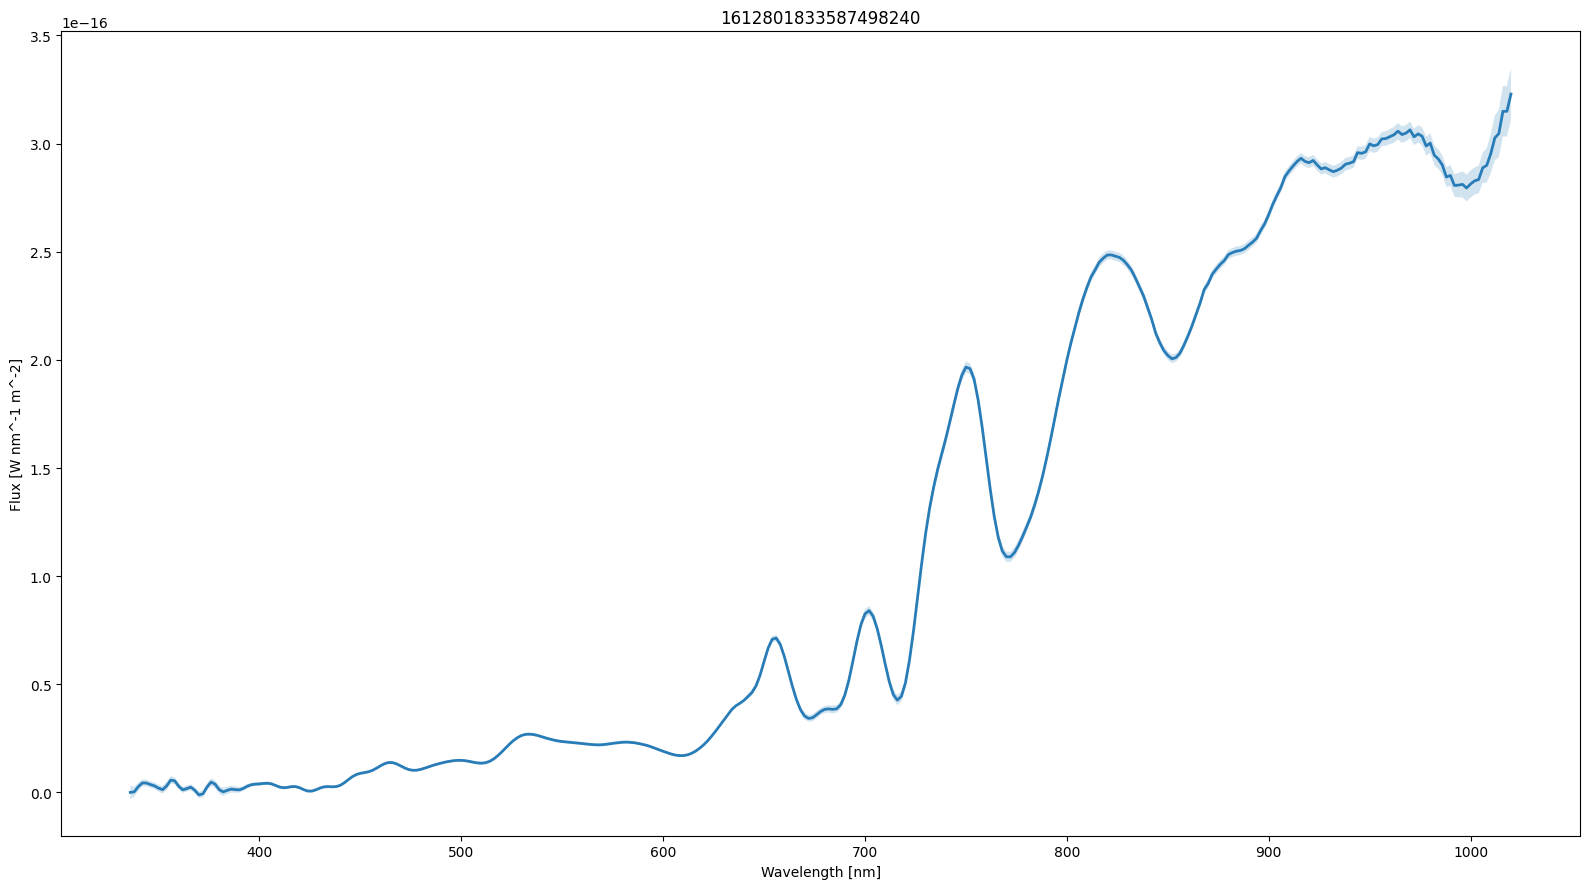

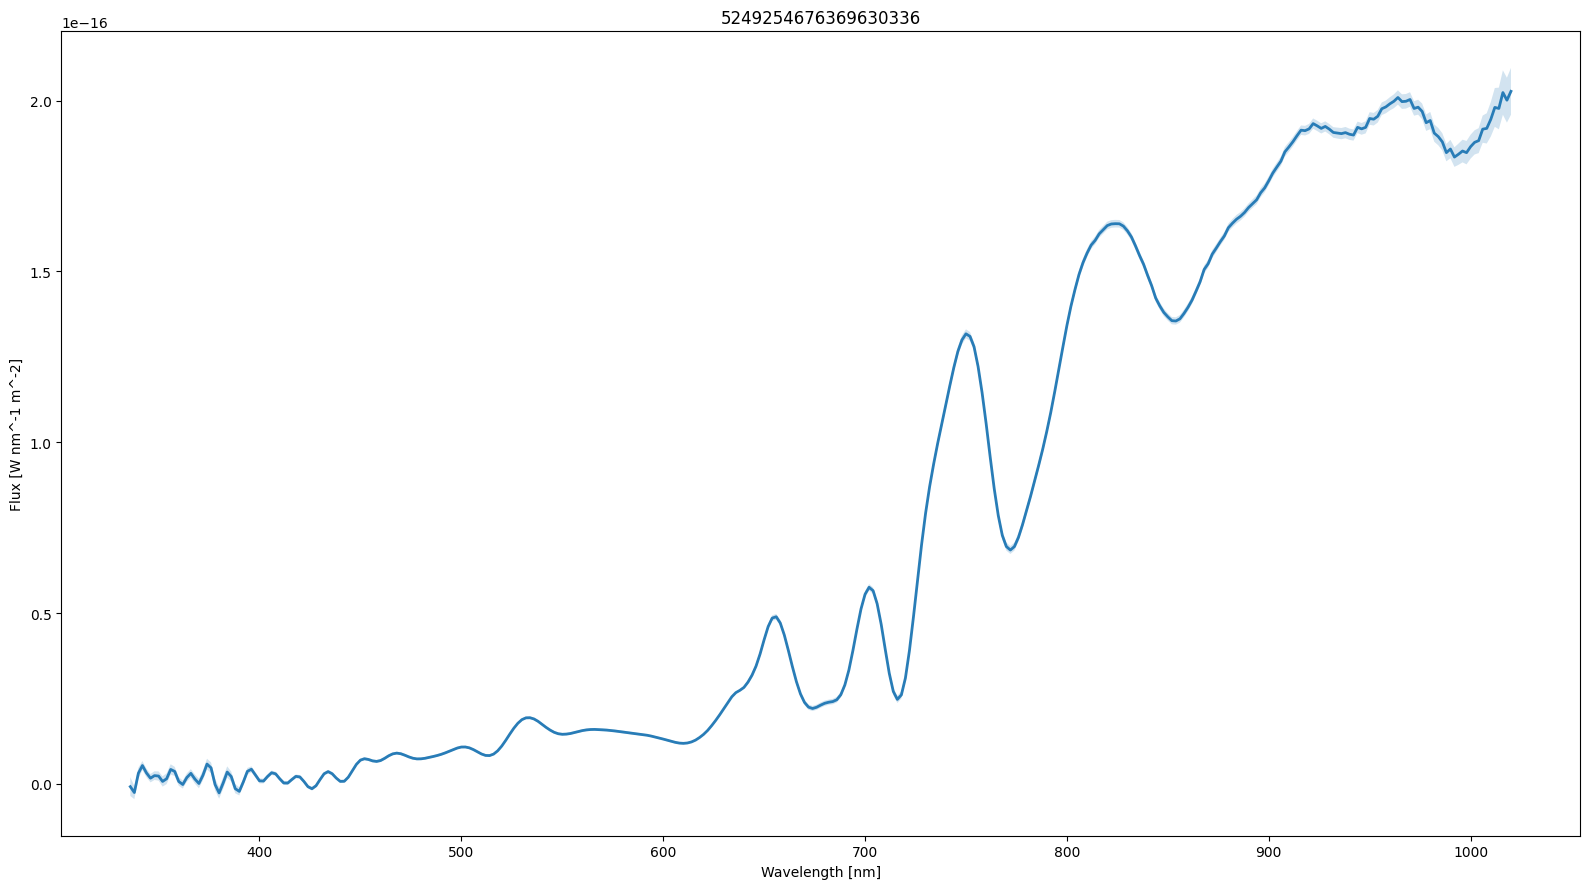

In [15]:
# externally calibrate the spectra
calibrated_spectra, sampling = calibrate(cdf, save_file = False)

# plot the spectra
plot_spectra(calibrated_spectra, sampling = sampling, legend = True)

* [Gaia DR3 XP spectra online documentation](https://gea.esac.esa.int/archive/documentation/GDR3/Data_processing/chap_cu5pho/cu5pho_sec_specProcessing/cu5pho_ssec_specInternCal.html#SSS3)
* [Gaia DR3 spectroscopic data model](https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_spectroscopic_tables/)
* [GaiaXPy website](https://gaia-dpci.github.io/GaiaXPy-website/)
* [GaiaXPy API documentation](https://gaiaxpy.readthedocs.io/en/latest/gaiaxpy.html)